# PCOS Data Analysis & Classification
Dataset: PCOS_data.csv (sheet `Full_new`). Target column: `PCOS (Y/N)`.

## 1. Imports

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

sns.set_style('whitegrid')
%matplotlib inline

## 2. Load Data
Read the CSV file exported from the PCOS Excel dataset.

In [5]:
import pandas as pd 

df =  pd.read_csv('augmented_pcos.csv')

In [6]:
df.head()

,Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),PCOS (Y/N)
0,31,55.3,159.799,23.022600,15,72,18,10.42,2,5,...,0.0,0,110,80,3,11,18.1,16.08,5.63,0
1,35,66.8,157.808,24.641938,15,72,18,10.66,2,5,...,1.0,0,120,80,3,2,19.5,20.44,4.14,0
2,37,63.5,154.713,23.886189,15,72,18,10.98,2,5,...,0.0,0,120,80,3,0,14.2,18.84,8.84,0
3,32,56.6,151.987,30.392813,15,72,18,11.20,2,5,...,1.0,0,110,80,4,13,12.0,11.26,9.63,0
4,30,55.0,162.000,20.957171,12,72,18,11.20,2,6,...,1.0,1,120,70,5,6,12.0,15.00,8.50,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1932 entries, 0 to 1931
Data columns (total 42 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age (yrs)               1932 non-null   int64  
 1   Weight (Kg)             1932 non-null   float64
 2   Height(Cm)              1932 non-null   float64
 3   BMI                     1932 non-null   float64
 4   Blood Group             1932 non-null   int64  
 5   Pulse rate(bpm)         1932 non-null   int64  
 6   RR (breaths/min)        1932 non-null   int64  
 7   Hb(g/dl)                1932 non-null   float64
 8   Cycle(R/I)              1932 non-null   int64  
 9   Cycle length(days)      1932 non-null   int64  
 10  Marraige Status (Yrs)   1932 non-null   float64
 11  Pregnant(Y/N)           1932 non-null   int64  
 12  No. of aborptions       1932 non-null   int64  
 13  I   beta-HCG(mIU/mL)    1932 non-null   float64
 14  II    beta-HCG(mIU/mL)  1932 non-null   

## 3. Data Cleaning
Drop identifier columns and empty/unnamed columns. Fix columns wrongly read as text (object) due to stray characters, and handle missing values.

In [8]:
df = df.drop(columns=['Sl. No', 'Patient File No.'], errors='ignore')
df = df.loc[:, ~df.columns.str.contains('Unnamed')]
df.columns = df.columns.str.strip()
df.shape

(1932, 42)

In [9]:
for col in ['II    beta-HCG(mIU/mL)'.strip(), 'AMH(ng/mL)']:
    col = col.strip()
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [10]:
df = df.fillna(df.median(numeric_only=True))
df.isnull().sum().sum()

np.int64(0)

## 4. Exploratory Data Analysis

### 4.1 Target distribution

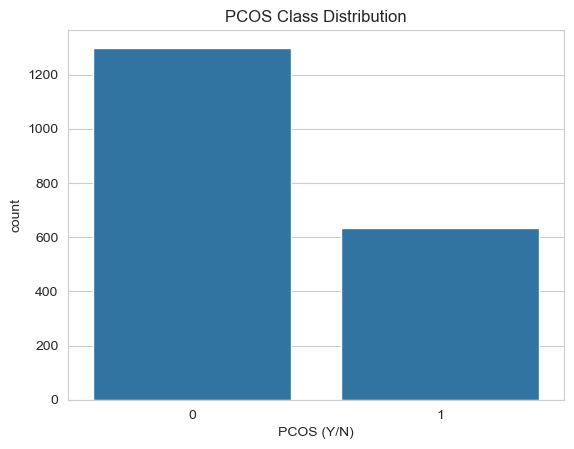

PCOS (Y/N)
0    0.67236
1    0.32764
Name: proportion, dtype: float64

In [11]:
target = 'PCOS (Y/N)'
sns.countplot(x=target, data=df)
plt.title('PCOS Class Distribution')
plt.show()
df[target].value_counts(normalize=True)

### 4.2 Summary statistics

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age (yrs),1932.0,31.196687,5.371312,20.000000,27.000000,31.000000,35.000000,48.000000
Weight (Kg),1932.0,58.834731,9.282896,31.000000,53.300000,58.700000,64.200000,108.000000
Height(Cm),1932.0,156.336928,5.468051,137.000000,152.039500,156.149500,160.287250,180.000000
BMI,1932.0,24.854938,4.070335,12.417882,22.132099,24.600000,27.645856,38.900000
Blood Group,1932.0,14.414596,1.318495,11.000000,15.000000,15.000000,15.000000,18.000000
Pulse rate(bpm),1932.0,72.486542,2.450615,13.000000,72.000000,72.000000,72.000000,82.000000
RR (breaths/min),1932.0,18.656832,1.151290,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),1932.0,10.818794,0.592917,9.000000,10.440000,10.790000,11.100000,14.800000
Cycle(R/I),1932.0,2.428054,0.821450,2.000000,2.000000,2.000000,2.000000,5.000000
Cycle length(days),1932.0,4.807453,1.055766,0.000000,5.000000,5.000000,5.000000,12.000000


### 4.3 Correlation with target

In [13]:
corr = df.corr(numeric_only=True)[target].sort_values(ascending=False)
corr

PCOS (Y/N)                1.000000
Follicle No. (R)          0.669404
Skin darkening (Y/N)      0.656977
Follicle No. (L)          0.616514
hair growth(Y/N)          0.576266
Cycle(R/I)                0.545250
Fast food (Y/N)           0.512515
Weight gain(Y/N)          0.503898
Pimples(Y/N)              0.460170
AMH(ng/mL)                0.454936
Hair loss(Y/N)            0.344032
Waist(inch)               0.236411
Weight (Kg)               0.224660
BMI                       0.223603
Hip(inch)                 0.221485
Avg. F size (R) (mm)      0.138131
Avg. F size (L) (mm)      0.116877
Height(Cm)                0.110302
Endometrium (mm)          0.104971
RBS(mg/dl)                0.104305
LH(mIU/mL)                0.095954
Blood Group               0.080784
Hb(g/dl)                  0.075595
Pulse rate(bpm)           0.074279
BP _Systolic (mmHg)       0.060804
RR (breaths/min)          0.048122
Vit D3 (ng/mL)            0.043010
Waist:Hip Ratio           0.036855
Reg.Exercise(Y/N)   

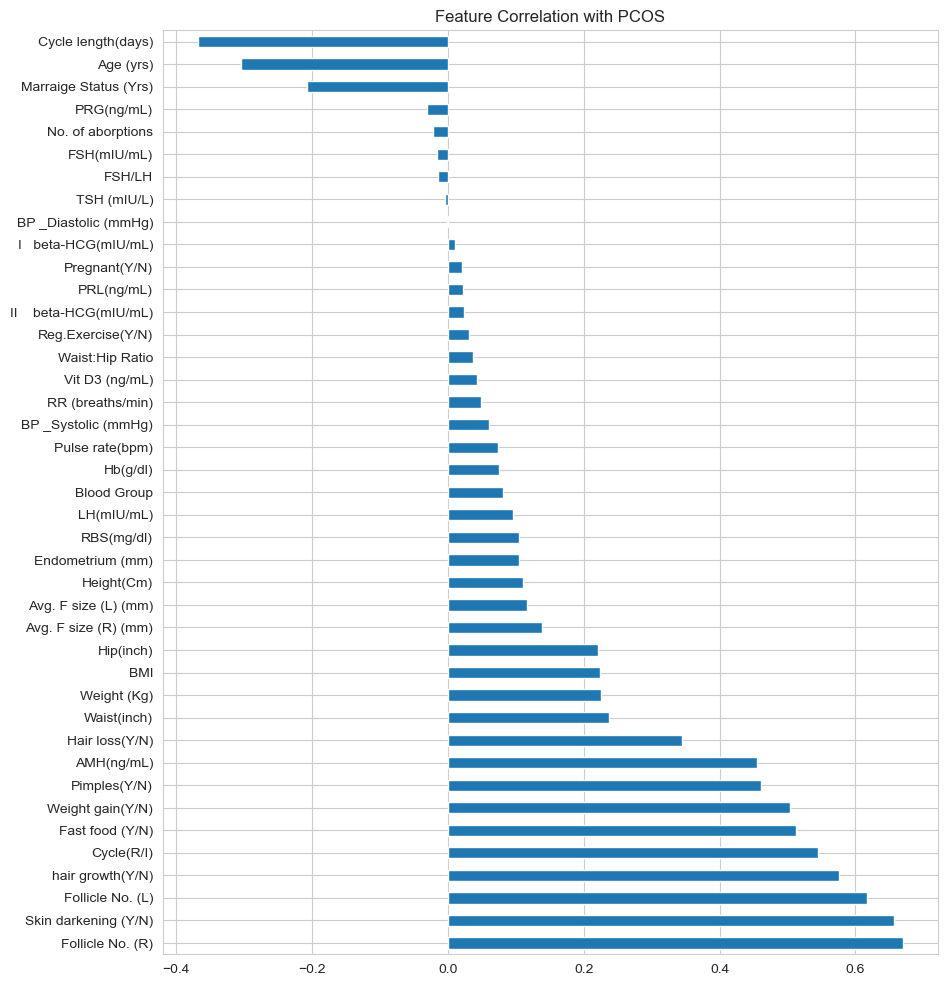

In [14]:
plt.figure(figsize=(10,12))
corr.drop(target).plot(kind='barh')
plt.title('Feature Correlation with PCOS')
plt.show()

### 4.4 Correlation heatmap

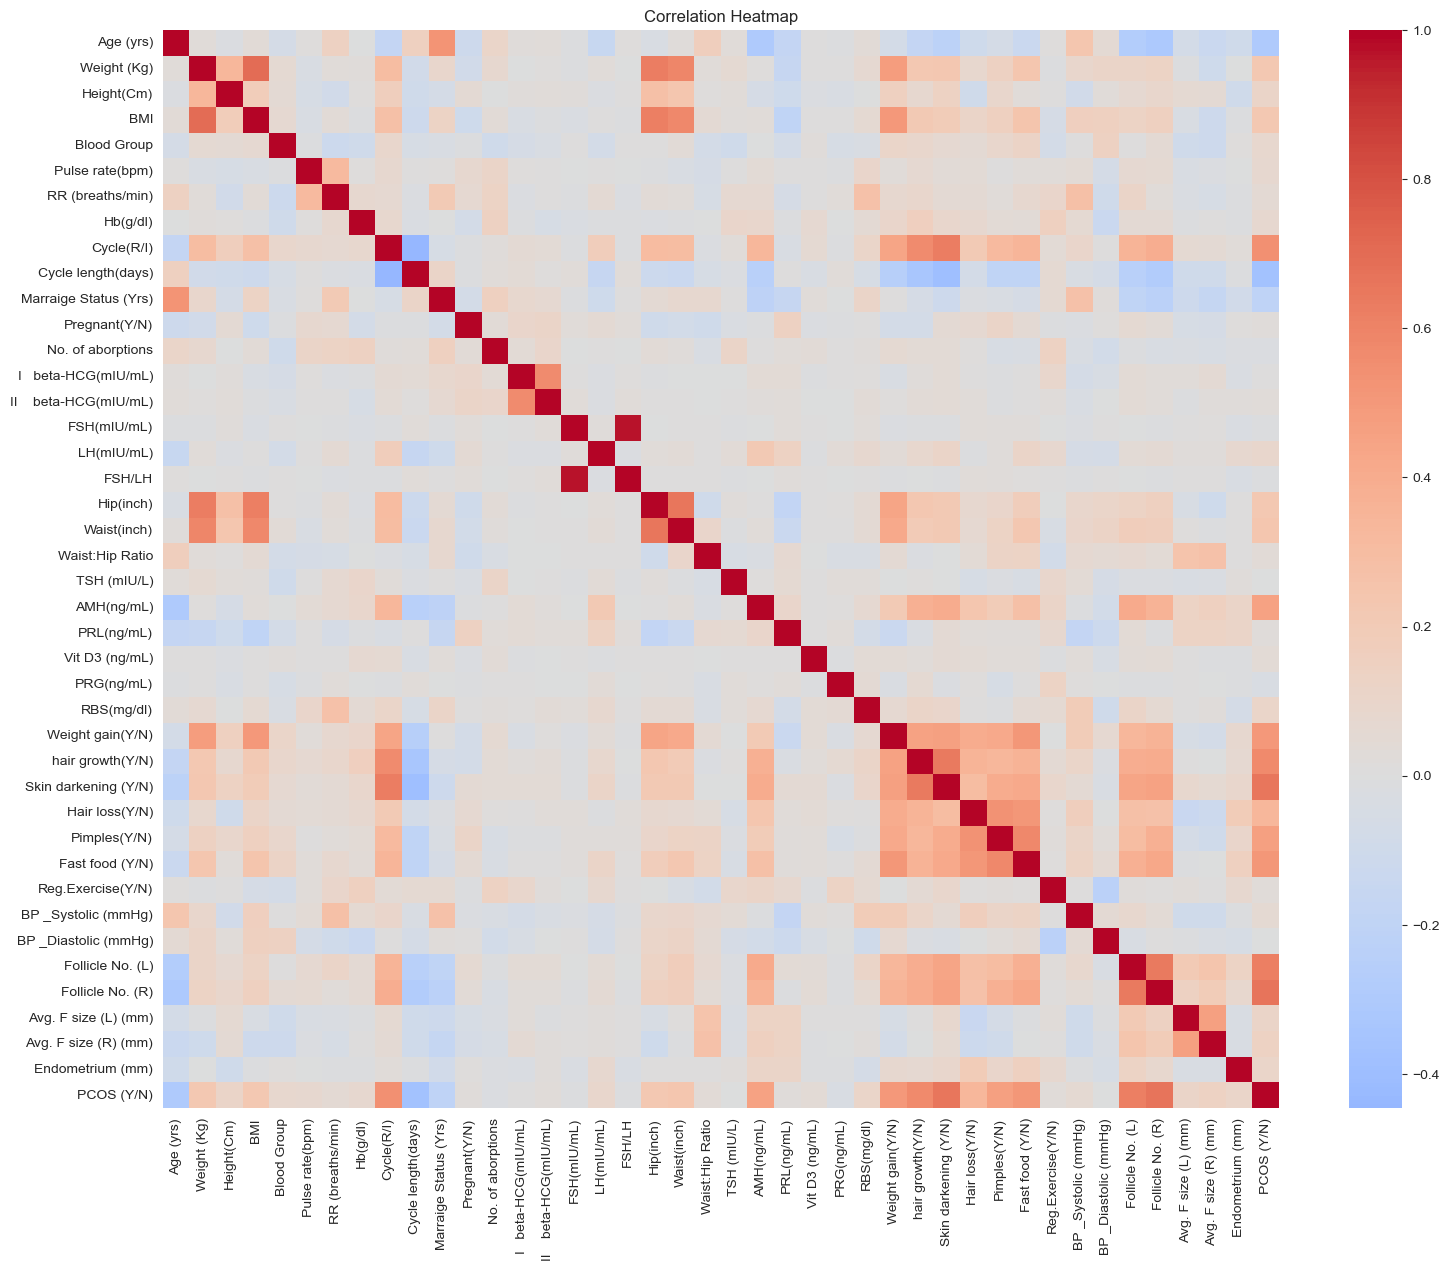

In [15]:
plt.figure(figsize=(18,14))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

### 4.5 Key feature distributions by PCOS status

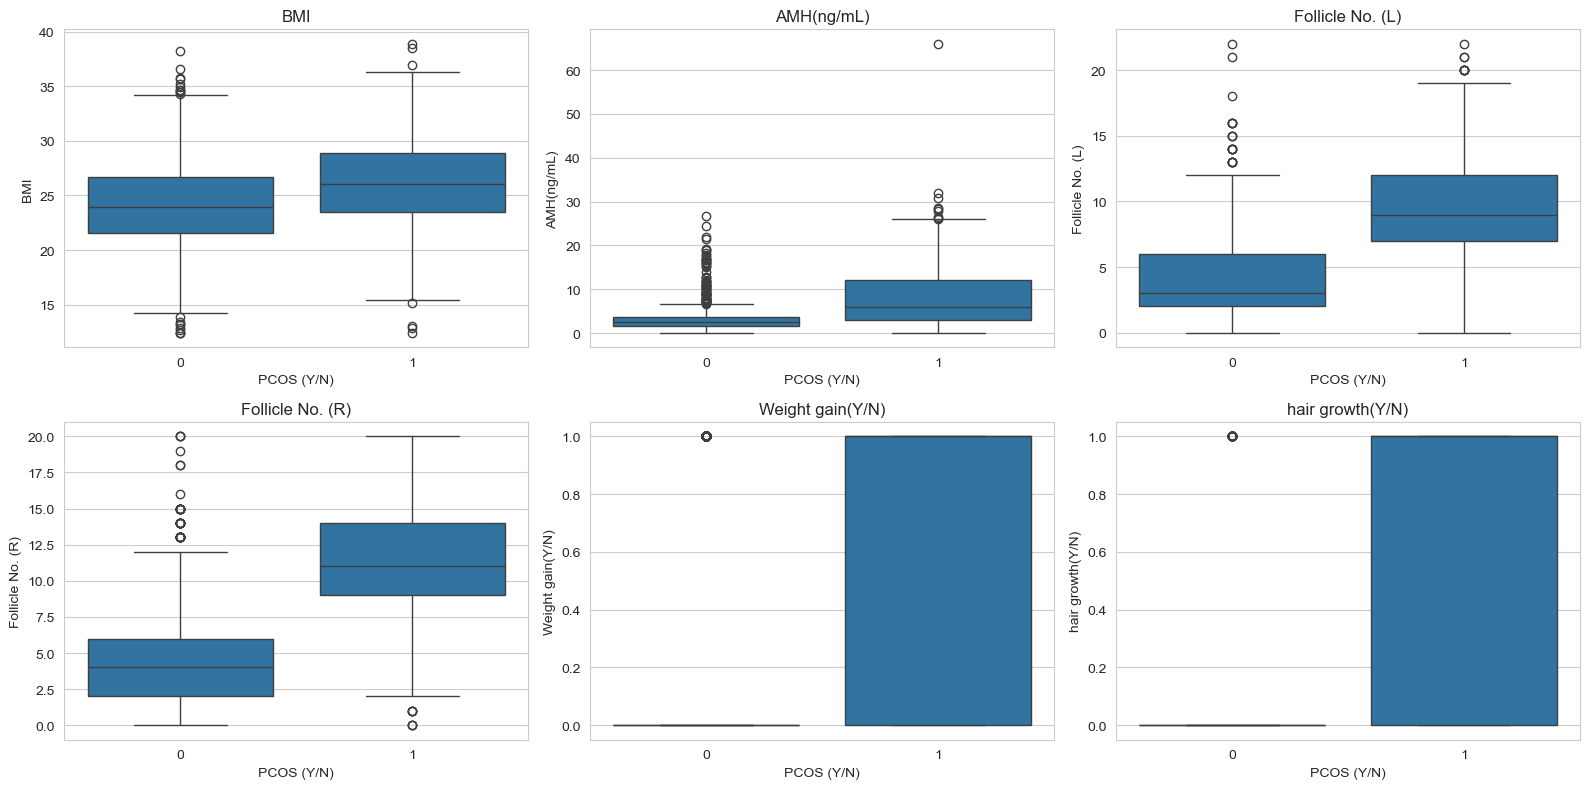

In [16]:
key_features = ['BMI', 'AMH(ng/mL)', 'Follicle No. (L)', 'Follicle No. (R)', 'Weight gain(Y/N)', 'hair growth(Y/N)']
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, feat in zip(axes.flatten(), key_features):
    sns.boxplot(x=target, y=feat, data=df, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

In [17]:
X = df.drop(columns=[target])
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape

((1545, 41), (387, 41))

Scale features for the logistic regression model.

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Train Models

### 6.1 Logistic Regression

In [19]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       260
           1       0.95      0.87      0.91       127

    accuracy                           0.94       387
   macro avg       0.94      0.92      0.93       387
weighted avg       0.94      0.94      0.94       387



### 6.2 Random Forest

In [20]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       260
           1       0.95      0.87      0.91       127

    accuracy                           0.94       387
   macro avg       0.94      0.93      0.93       387
weighted avg       0.94      0.94      0.94       387



### 6.3 XGB

In [29]:
xgb = XGBClassifier(n_estimators=300, random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.95      0.96      0.95       260
           1       0.91      0.89      0.90       127

    accuracy                           0.94       387
   macro avg       0.93      0.92      0.93       387
weighted avg       0.94      0.94      0.94       387



### 6.4 SVM

In [31]:
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.67      1.00      0.80       260
           1       1.00      0.01      0.02       127

    accuracy                           0.67       387
   macro avg       0.84      0.50      0.41       387
weighted avg       0.78      0.67      0.55       387



### 6.5 GBC

In [32]:
GBC = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

GBC.fit(X_train, y_train)
y_pred_GBC = GBC.predict(X_test)
print(classification_report(y_test, y_pred_GBC))

              precision    recall  f1-score   support

           0       0.94      0.97      0.96       260
           1       0.93      0.88      0.91       127

    accuracy                           0.94       387
   macro avg       0.94      0.93      0.93       387
weighted avg       0.94      0.94      0.94       387



## 7. Model Evaluation

### 7.1 Confusion matrices

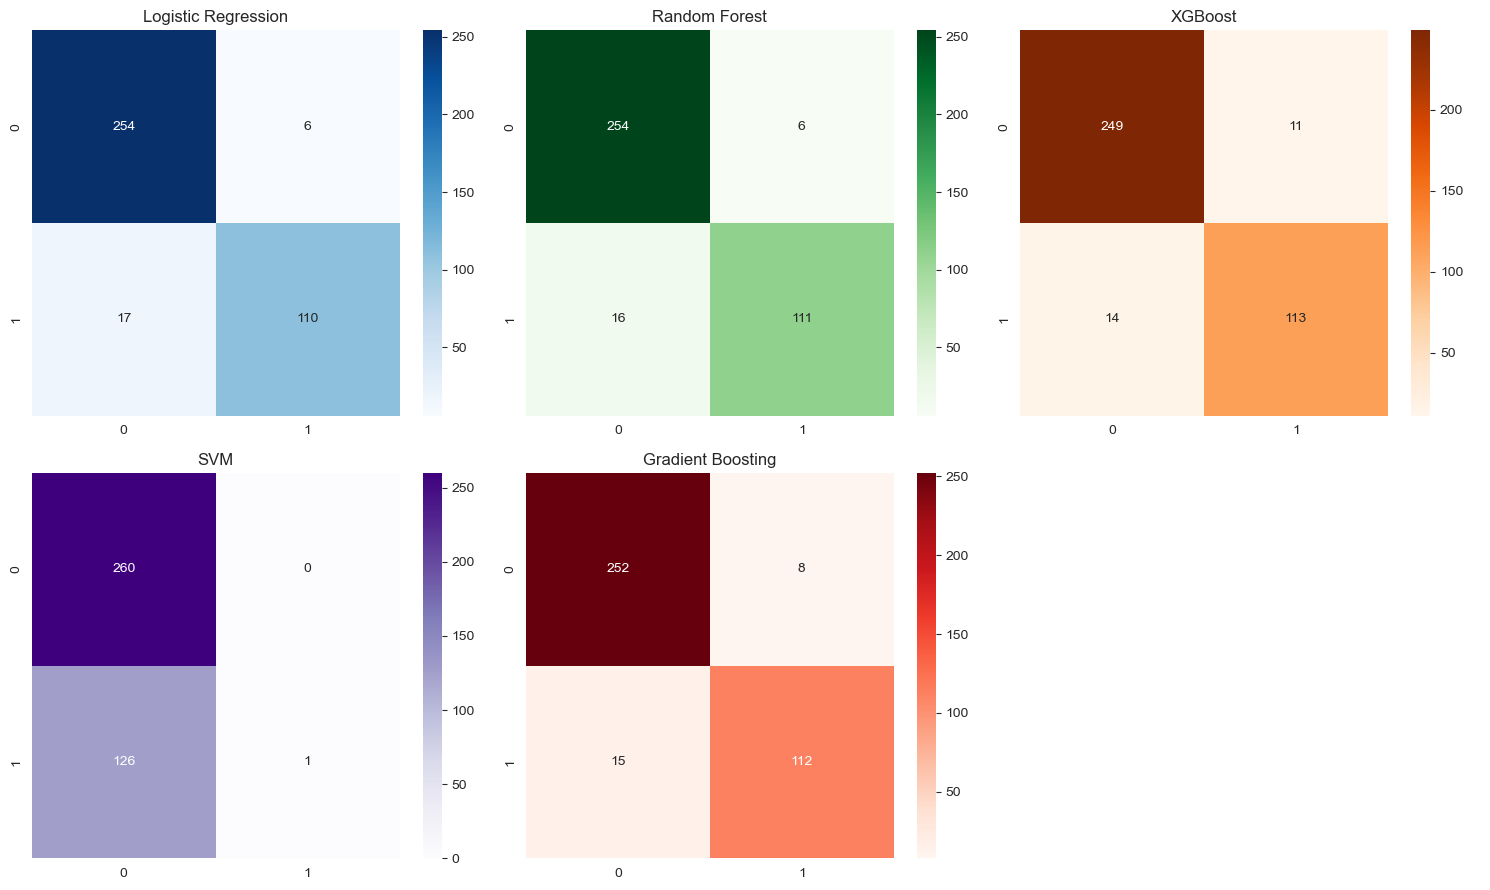

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Logistic Regression
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d',
            ax=axes[0, 0], cmap='Blues')
axes[0, 0].set_title('Logistic Regression')

# Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d',
            ax=axes[0, 1], cmap='Greens')
axes[0, 1].set_title('Random Forest')

# XGBoost
sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d',
            ax=axes[0, 2], cmap='Oranges')
axes[0, 2].set_title('XGBoost')

# SVM
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d',
            ax=axes[1, 0], cmap='Purples')
axes[1, 0].set_title('SVM')

# Gradient Boosting
sns.heatmap(confusion_matrix(y_test, y_pred_GBC), annot=True, fmt='d',
            ax=axes[1, 1], cmap='Reds')
axes[1, 1].set_title('Gradient Boosting')

# Hide the unused sixth subplot
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### 7.2 ROC curves

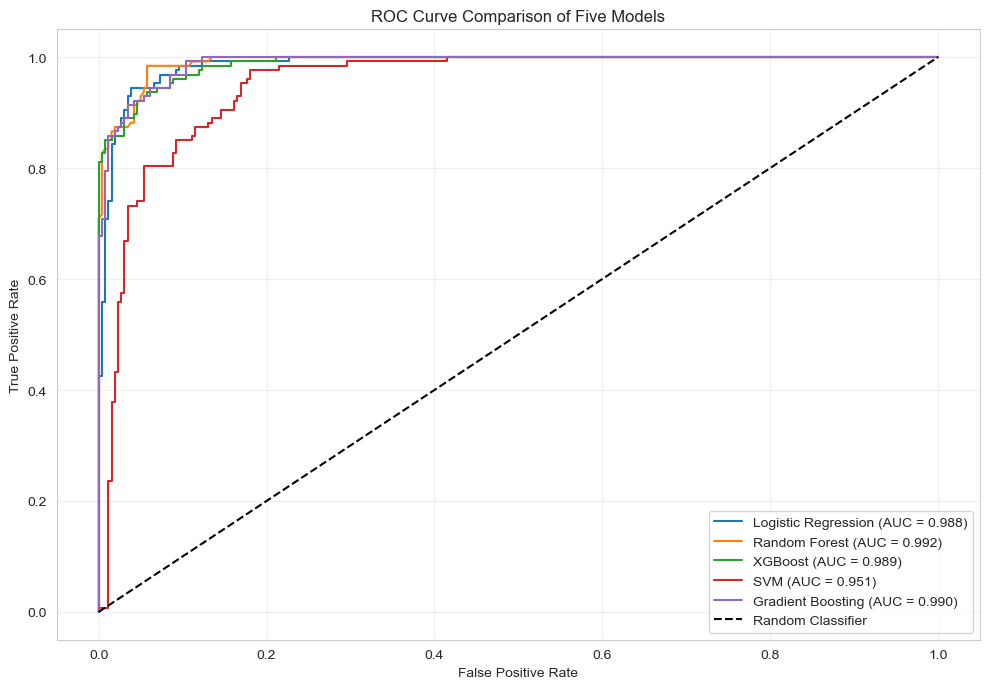

In [35]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get prediction scores
probs_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
probs_rf = rf.predict_proba(X_test)[:, 1]
probs_xgb = xgb.predict_proba(X_test)[:, 1]

# SVM: Use decision_function instead of predict_proba
probs_svm = svm.decision_function(X_test)

probs_gbc = GBC.predict_proba(X_test)[:, 1]

# Store models and their scores
models = {
    'Logistic Regression': probs_lr,
    'Random Forest': probs_rf,
    'XGBoost': probs_xgb,
    'SVM': probs_svm,
    'Gradient Boosting': probs_gbc
}

# Plot ROC curves
plt.figure(figsize=(10, 7))

for name, scores in models.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_score = roc_auc_score(y_test, scores)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})')

# Random classifier baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Five Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Feature importance (Random Forest)

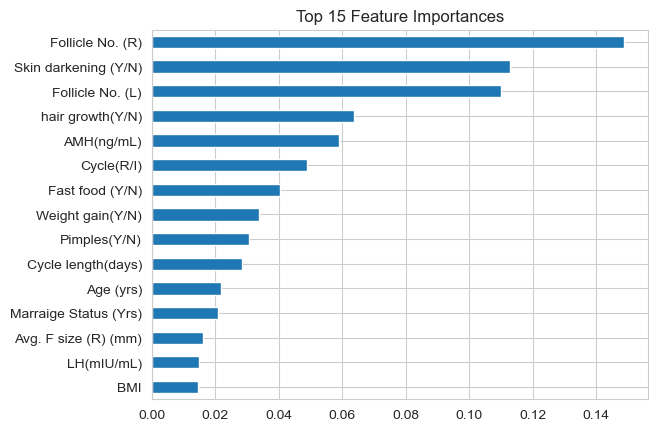

In [36]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances')
plt.show()

### 7.4 Cross-validation

In [37]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Logistic Regression (with scaling)
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', log_reg)
])

cv_scores_lr = cross_val_score(
    pipeline_lr, X, y, cv=5, scoring='accuracy'
)

# Random Forest
cv_scores_rf = cross_val_score(
    rf, X, y, cv=5, scoring='accuracy'
)

# XGBoost
cv_scores_xgb = cross_val_score(
    xgb, X, y, cv=5, scoring='accuracy'
)

# SVM (with scaling)
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('model', svm)
])

cv_scores_svm = cross_val_score(
    pipeline_svm, X, y, cv=5, scoring='accuracy'
)

# Gradient Boosting
cv_scores_gbc = cross_val_score(
    GBC, X, y, cv=5, scoring='accuracy'
)

# Display results
print('Logistic Regression CV Accuracy:', round(cv_scores_lr.mean(), 3))
print('Random Forest CV Accuracy:', round(cv_scores_rf.mean(), 3))
print('XGBoost CV Accuracy:', round(cv_scores_xgb.mean(), 3))
print('SVM CV Accuracy:', round(cv_scores_svm.mean(), 3))
print('Gradient Boosting CV Accuracy:', round(cv_scores_gbc.mean(), 3))

Logistic Regression CV Accuracy: 0.924
Random Forest CV Accuracy: 0.927
XGBoost CV Accuracy: 0.917
SVM CV Accuracy: 0.924
Gradient Boosting CV Accuracy: 0.926


In [38]:
import pickle

with open('rf_pcos_model.pkl', 'wb') as f:
    pickle.dump(rf, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('Model and scaler saved.')

Model and scaler saved.


In [39]:
with open('rf_pcos_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

loaded_model.predict(X_test)

array([0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0,

## 8. Conclusion
Compare both models and pick the one with better recall/AUC for PCOS detection, since false negatives are more costly in a medical screening context.